# Proyecto 1 — Precios, retornos y riesgo

**Objetivo:** al terminar sabrás transformar precios en retornos, medir riesgo (volatilidad, drawdown), evaluar rendimiento ajustado por riesgo (Sharpe) y ver cómo se mueven los activos entre sí (correlación). Todo lo que viene después (backtesting, portafolios, pricing) se construye sobre esto.

**Regla del notebook:** cada sección tiene *concepto → código → qué mirar*. No sigas a la siguiente sin entender qué te dice el gráfico o la tabla.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from quantlab import (load_prices, simple_returns, log_returns, cumulative_returns,
                      rolling_volatility, drawdown, summary)

plt.rcParams["figure.figsize"] = (12, 5)
sns.set_theme(style="whitegrid")

## 1. Datos

Diez activos con perfiles distintos a propósito: tech grande, un banco, energía, consumo básico, un ETF del índice (SPY), bonos (TLT), oro (GLD) y un activo muy volátil (TSLA). Así las diferencias de riesgo saltan a la vista.

Usamos **precio ajustado** (incluye dividendos y splits). Si usas el `Close` sin ajustar, un split 2:1 aparece como una caída del 50% que no existió.

In [16]:
TICKERS = ["AAPL", "MSFT", "JPM", "XOM", "KO", "TSLA", "NVDA", "SPY", "TLT", "GLD"]
prices = load_prices(TICKERS, start="2019-01-01")
prices.tail()

Ticker,AAPL,GLD,JPM,KO,MSFT,NVDA,SPY,TLT,TSLA,XOM
Date,,,,,,,,,,
2026-09-02,324.959991,402.779999,356.220001,88.239998,496.820007,224.410004,765.159973,81.949997,357.010010,164.149994
2026-09-03,328.209991,410.220001,362.059998,88.809998,510.119995,228.449997,773.169983,82.070000,376.369995,162.210007
2026-09-04,319.970001,406.769989,358.640015,88.070000,499.700012,230.360001,770.190002,82.209999,354.079987,159.470001
2026-09-08,316.220001,399.720001,353.510010,88.360001,493.950012,225.729996,765.960022,82.199997,368.160004,160.660004
2026-09-09,315.339996,403.350006,354.709991,87.550003,491.649994,223.669998,762.400024,81.730003,367.809998,164.229996


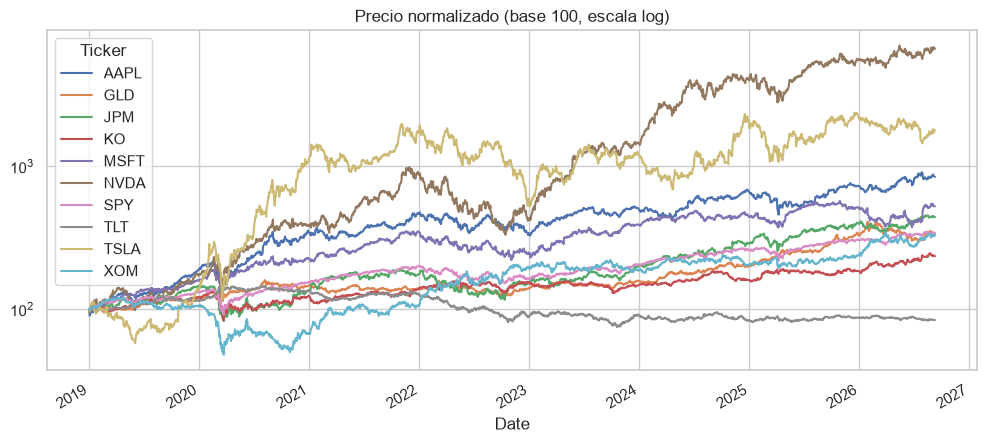

In [17]:
# Normalizamos a 100 el primer día para comparar trayectorias
(prices / prices.iloc[0] * 100).plot(logy=True, title="Precio normalizado (base 100, escala log)")
plt.show()

**Qué mirar:** la escala logarítmica hace que la misma pendiente signifique el mismo % de crecimiento. Un movimiento de 10 a 20 y de 100 a 200 se ven iguales. Sin escala log, NVDA aplasta todo lo demás y no ves nada.

## 2. De precios a retornos

Los precios no se pueden comparar entre activos (una acción de 500 no es "mejor" que una de 50) ni son estacionarios (su media cambia con el tiempo). Por eso **todo el análisis se hace sobre retornos**, no sobre precios.

Dos definiciones:

- **Retorno simple**: $r_t = \frac{P_t}{P_{t-1}} - 1$. Es lo que ves en tu cuenta. Se *multiplica* en el tiempo: $(1+r_1)(1+r_2)\cdots$
- **Retorno logarítmico**: $r_t = \ln\frac{P_t}{P_{t-1}}$. Se *suma* en el tiempo: $r_1 + r_2 + \cdots = \ln\frac{P_T}{P_0}$

Para movimientos pequeños (< 5%) son casi idénticos. Los log-retornos son más cómodos para modelar (sumas, distribución más simétrica); los simples son los correctos para calcular cuánto dinero tienes.

In [18]:
rets = simple_returns(prices)
lrets = log_returns(prices)

# Comparación en un día tranquilo y en uno extremo de TSLA
comp = pd.DataFrame({"simple": rets["TSLA"], "log": lrets["TSLA"]})
comp["diferencia"] = comp["simple"] - comp["log"]
comp.loc[comp["simple"].abs().nlargest(3).index]

,simple,log,diferencia
Date,,,
2025-04-09,0.226900,0.204491,0.022409
2024-10-24,0.219190,0.198187,0.021003
2020-09-08,-0.210628,-0.236518,0.025890


In [19]:
# Verifica la propiedad aditiva: la suma de log-retornos recupera el retorno total
total_log = lrets["AAPL"].sum()
total_real = np.log(prices["AAPL"].iloc[-1] / prices["AAPL"].iloc[0])
print(f"suma de log-retornos: {total_log:.4f}   ln(P_T/P_0): {total_real:.4f}")

suma de log-retornos: 2.1310   ln(P_T/P_0): 2.1310


**Qué mirar:** en días normales la diferencia es ~0. En un día de +20% el log-retorno es 18.2%: el log siempre "aplana" los extremos. Recuerda esto cuando compares Sharpe entre fuentes: si una usa log y otra simple, no son comparables.

## 3. ¿Cómo se distribuyen los retornos?

El supuesto más común (y más falso) en finanzas es que los retornos son normales. Veámoslo.

- **Skew** (asimetría): 0 en una normal. Negativo = las caídas grandes son más frecuentes que las subidas grandes.
- **Curtosis** (exceso): 0 en una normal. Positivo = **colas gordas**: los eventos extremos ocurren mucho más de lo que la normal predice. Esto es lo que quiebra fondos.

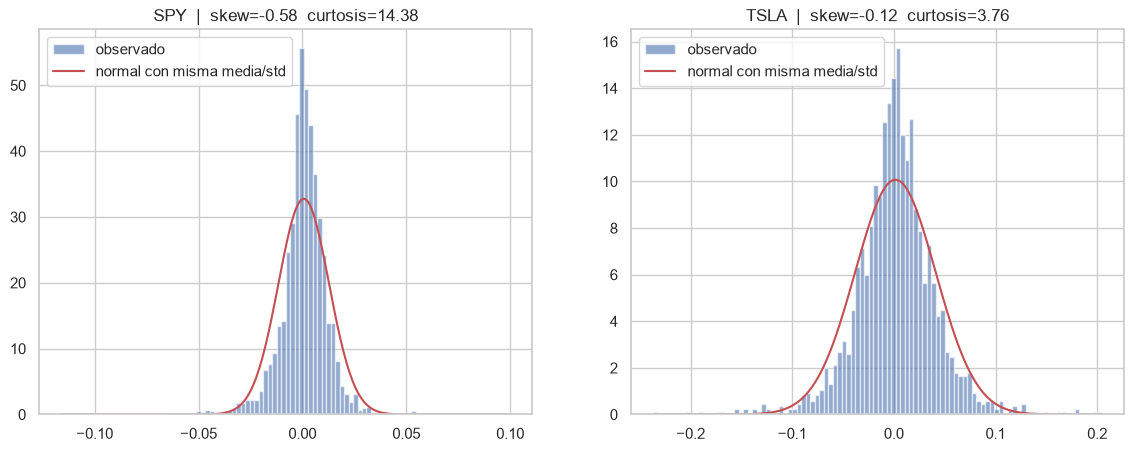

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, t in zip(axes, ["SPY", "TSLA"]):
    r = lrets[t]
    ax.hist(r, bins=100, density=True, alpha=0.6, label="observado")
    x = np.linspace(r.min(), r.max(), 300)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r-", label="normal con misma media/std")
    ax.set_title(f"{t}  |  skew={r.skew():.2f}  curtosis={r.kurtosis():.2f}")
    ax.legend()
plt.show()

In [21]:
# ¿Cuántas veces SPY se movió más de 4 desviaciones estándar?
r = lrets["SPY"]
z = (r - r.mean()) / r.std()
n_extremos = (z.abs() > 4).sum()
esperado_normal = len(r) * 2 * (1 - stats.norm.cdf(4))
print(f"Días con |z| > 4: {n_extremos}   Esperado si fuera normal: {esperado_normal:.3f}")

Días con |z| > 4: 16   Esperado si fuera normal: 0.122


**Qué mirar:** el pico central es más alto y las colas más anchas que la normal. Bajo normalidad, un movimiento de 4σ debería ocurrir una vez cada ~60 años; en la práctica ocurren varias veces por década. **Todo modelo que asuma normalidad subestima el riesgo de cola.** Este es el punto más importante del notebook.

## 4. Volatilidad

Volatilidad = desviación estándar de los retornos. Es *la* medida estándar de riesgo.

**Anualizar:** la varianza es aditiva en el tiempo (si los retornos son independientes), así que $\sigma_{anual} = \sigma_{diaria} \cdot \sqrt{252}$. Ojo: raíz de 252, no 252.

Pero la volatilidad **no es constante**: hay períodos calmados y períodos de pánico (marzo 2020). Por eso se mira con ventana móvil.

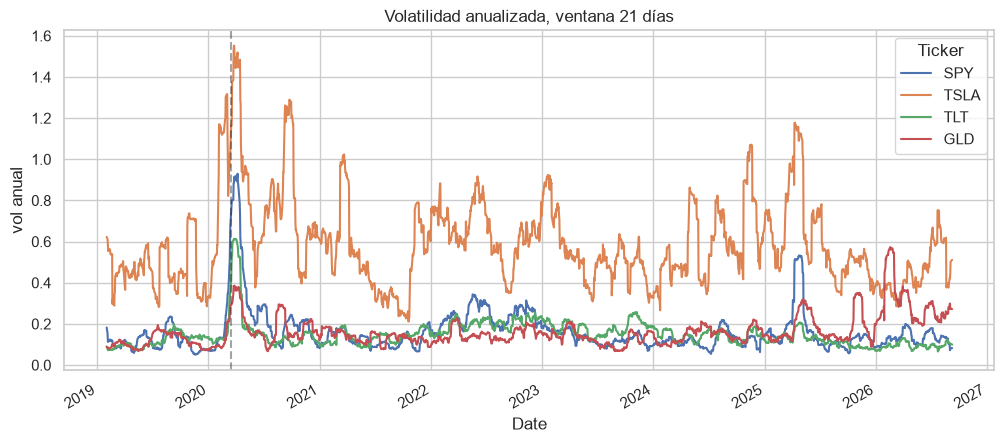

In [22]:
vol_21 = rolling_volatility(rets, window=21)  # ~1 mes hábil
vol_21[["SPY", "TSLA", "TLT", "GLD"]].plot(title="Volatilidad anualizada, ventana 21 días")
plt.axvline(pd.Timestamp("2020-03-16"), color="k", ls="--", alpha=0.4)
plt.ylabel("vol anual")
plt.show()

**Qué mirar:** (1) TSLA vive en un régimen de volatilidad 3-4x el de SPY. (2) En marzo 2020 *todo* subió a la vez, incluso el oro y los bonos: en una crisis las correlaciones tienden a 1, justo cuando más necesitas diversificación. (3) La volatilidad tiene **clustering**: días volátiles vienen seguidos de días volátiles. Esto es lo que modela GARCH (Fase 1).

## 5. Drawdown

La volatilidad te dice cuánto se mueve un activo, pero no cuánto dolor sientes. **Drawdown** = qué tan lejos estás del máximo histórico. **Max drawdown** = la peor caída pico-a-valle.

Un fondo con Sharpe alto pero max drawdown del -60% es uno que ningún cliente aguantó hasta la recuperación.

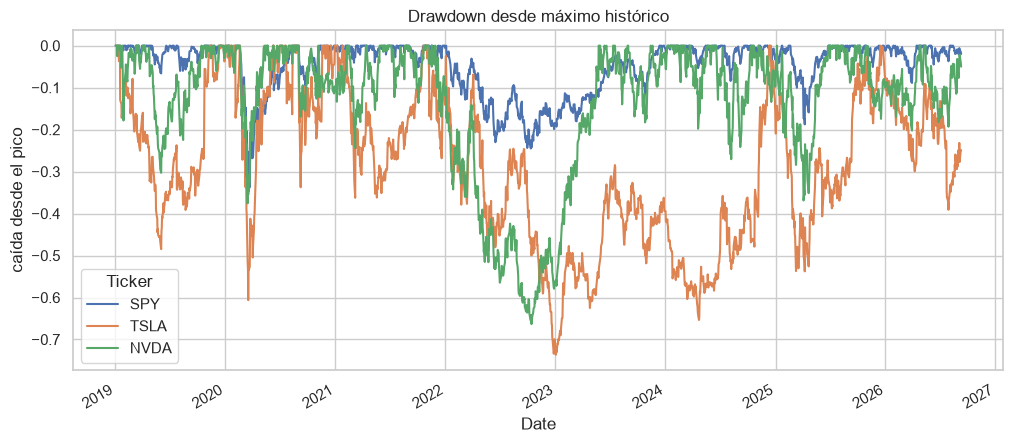

In [23]:
dd = drawdown(rets)
dd[["SPY", "TSLA", "NVDA"]].plot(title="Drawdown desde máximo histórico")
plt.ylabel("caída desde el pico")
plt.show()

In [24]:
# Para recuperarte de una caída del x% necesitas subir más de x%
caidas = np.array([0.10, 0.25, 0.50, 0.75])
pd.DataFrame({"caída": caidas, "subida necesaria": 1 / (1 - caidas) - 1})

,caída,subida necesaria
0,0.10,0.111111
1,0.25,0.333333
2,0.50,1.000000
3,0.75,3.000000


**Qué mirar:** la asimetría. Caer 50% exige subir 100% para volver. Por eso el control de drawdown vale más que perseguir retorno.

## 6. Rendimiento ajustado por riesgo: Sharpe

$$\text{Sharpe} = \frac{E[r] - r_f}{\sigma}$$

Retorno extra sobre la tasa libre de riesgo por unidad de volatilidad. Referencias aproximadas: SPY a largo plazo ~0.4-0.6; un fondo bueno >1; >2 sostenido en el tiempo es sospechoso (o es overfitting o hay riesgo escondido).

Aquí usamos $r_f = 0$ para simplificar; en la práctica usarías la tasa del T-bill a 3 meses.

In [25]:
tabla = summary(rets).sort_values("sharpe", ascending=False)
tabla.style.format({"ret_anual": "{:.1%}", "vol_anual": "{:.1%}", "max_drawdown": "{:.1%}",
                    "sharpe": "{:.2f}", "skew": "{:.2f}", "kurtosis": "{:.1f}"})

,ret_anual,vol_anual,sharpe,max_drawdown,skew,kurtosis
Ticker,,,,,,
NVDA,72.9%,50.6%,1.33,-66.3%,0.31,4.6
AAPL,32.1%,30.7%,1.06,-33.4%,0.13,6.7
GLD,17.0%,17.8%,0.97,-26.4%,-0.61,6.4
SPY,17.3%,19.3%,0.93,-33.7%,-0.29,14.0
TSLA,45.6%,63.0%,0.91,-73.6%,0.22,3.8
MSFT,24.1%,29.3%,0.88,-37.1%,0.30,9.0
JPM,21.4%,29.3%,0.81,-43.6%,0.33,13.5
XOM,17.0%,30.9%,0.66,-60.3%,-0.01,5.0
KO,11.8%,19.9%,0.66,-37.0%,-0.51,8.3


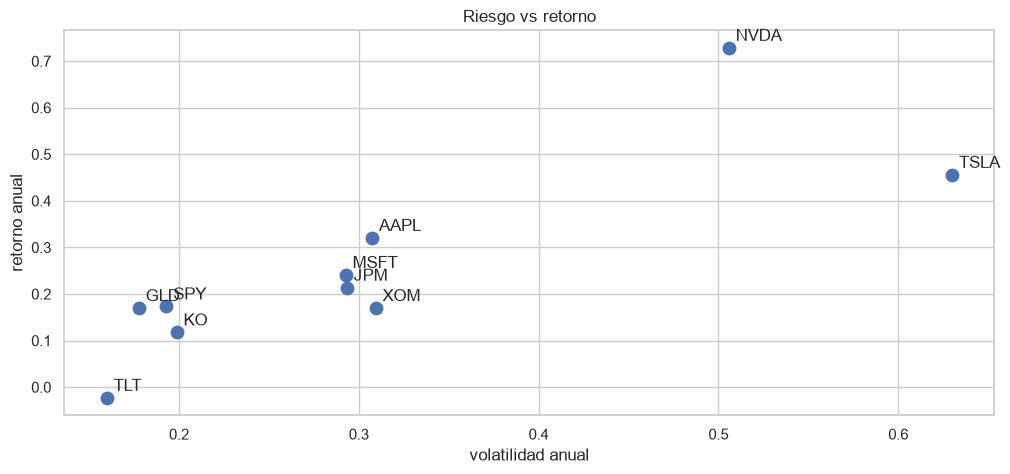

In [26]:
plt.scatter(tabla["vol_anual"], tabla["ret_anual"], s=80)
for t, row in tabla.iterrows():
    plt.annotate(t, (row["vol_anual"], row["ret_anual"]), xytext=(5, 5), textcoords="offset points")
plt.xlabel("volatilidad anual"); plt.ylabel("retorno anual")
plt.title("Riesgo vs retorno")
plt.show()

**Qué mirar:** el gráfico riesgo/retorno es el mapa mental de todo quant. Arriba a la izquierda = bueno. La pregunta que responde la optimización de portafolios (Fase 2) es: ¿puedo combinar estos puntos para crear uno mejor que todos ellos? Sí, si no están perfectamente correlacionados. Lo cual nos lleva a...

## 7. Correlación

Diversificar funciona porque los activos no se mueven juntos. La correlación mide eso: +1 idénticos, 0 independientes, -1 opuestos.

Se calcula sobre **retornos**, nunca sobre precios (dos precios que suben a largo plazo tienen correlación ~1 aunque no tengan nada que ver: es correlación espuria por tendencia).

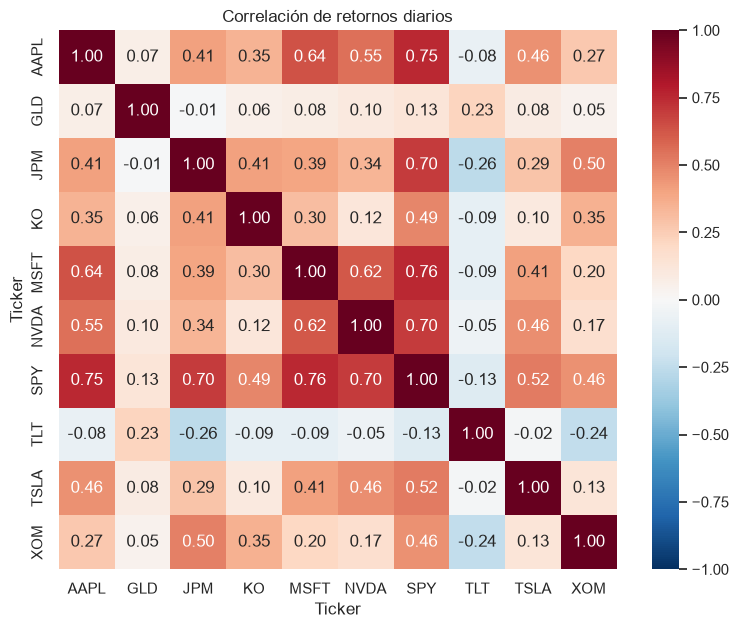

In [27]:
corr = rets.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación de retornos diarios")
plt.show()

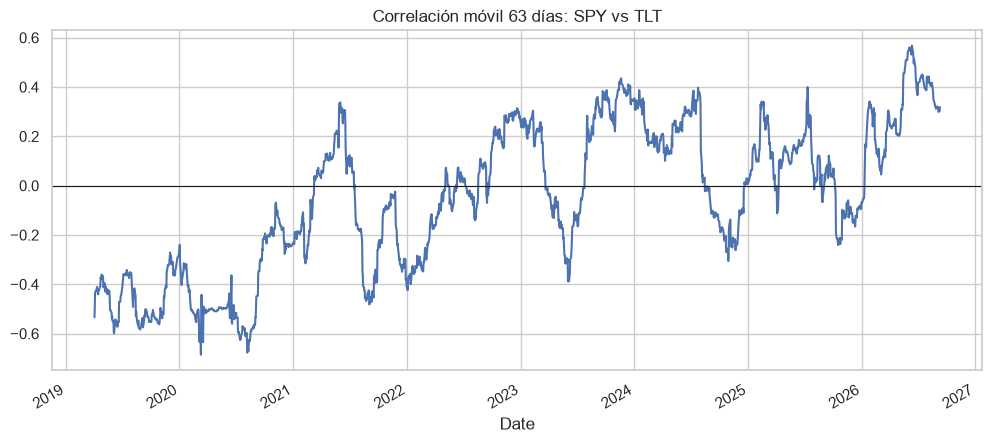

In [28]:
# La correlación tampoco es estable: SPY vs TLT (acciones vs bonos)
roll_corr = rets["SPY"].rolling(63).corr(rets["TLT"])  # 63 ≈ un trimestre
roll_corr.plot(title="Correlación móvil 63 días: SPY vs TLT")
plt.axhline(0, color="k", lw=0.8)
plt.show()

**Qué mirar:** (1) Las tech se correlacionan mucho entre sí: tener AAPL+MSFT+NVDA diversifica poco. (2) Oro y bonos son los que realmente diversifican frente a acciones. (3) La correlación acciones/bonos no es un número: fue negativa años (bonos protegían) y se volvió positiva en 2022 cuando ambos cayeron por la inflación. Cualquier modelo que use una correlación fija está asumiendo algo que no es cierto.

## 8. Ejercicios (hazlos, no los leas)

1. **Frecuencia.** Recalcula la tabla `summary` con retornos **semanales** (`prices.resample("W").last()`). ¿Cambia el Sharpe? ¿Cambia la curtosis? ¿Por qué la curtosis baja al agregar?
2. **Portafolio equiponderado.** Crea un portafolio con 10% en cada activo, rebalanceado diario (`rets.mean(axis=1)`). Añádelo a la tabla. ¿Tiene mejor Sharpe que la mayoría de sus componentes? ¿Menor max drawdown? Eso es diversificación en acción.
3. **Régimen de crisis.** Filtra solo marzo 2020 y recalcula la matriz de correlación. Compárala con la del período completo.
4. **Tu función.** Escribe en `metrics.py` una función `calmar_ratio(returns)` = retorno anual / |max drawdown|, con su test en `tests/test_metrics.py`. Corre `pytest`.
5. **Reto.** Escribe `sortino_ratio`: como Sharpe pero usando solo la desviación de los retornos negativos en el denominador. Investiga por qué algunos prefieren esto a Sharpe.

Cuando termines, haz commit y push. Siguiente proyecto: simulación Monte Carlo de precios (movimiento browniano geométrico), donde usaremos la media, la volatilidad y la correlación que acabas de calcular como inputs.